# Philippines News Headlines — Semantic (Context-Aware) Sentiment Analysis

**Companion to `news-headline.ipynb` (rule-based / bag-of-words).** That notebook scores a headline by the
*words* it contains (TF-IDF + TextBlob-generated labels), so a strong word like "bad" can dominate even in
"The president is **not** bad". This notebook instead reads the **whole sentence**: every headline is turned into a
*sentence embedding* (a vector that captures meaning and word order, including negation), and a classifier is trained
on top of it.

| | Rule-based notebook | This notebook (semantic) |
|---|---|---|
| Unit of analysis | individual words / bigrams | the whole sentence (and its phrases) |
| Labels | TextBlob polarity rule | a pretrained context-aware "teacher" model, validated on hand-checked data |
| Features | TF-IDF + length/punctuation metadata | sentence embeddings (MiniLM) |
| Classifier | Logistic Regression / SVM / NB | Logistic Regression / small neural net (MLP, trained with Adam) |
| Explanation | top weighted words | phrase-by-phrase impact (remove a phrase, see how the score moves) |
| UI | Streamlit | tkinter desktop app (`app_tk.py`) |

**Contents:** 1 Setup · 2 Data · 3 Labels (teacher) · 4 Split · 5 EDA · 6 Sentence embeddings ·
7 Neural-network foundations: perceptron, activations, loss, forward pass & backpropagation (from scratch) ·
8 Training dynamics: gradient descent, learning rate, **Adam**, overfitting & dropout (from scratch) ·
9 Models & tuning · 10 Test evaluation · 11 Packaging · 12 Negation stress test (rule-based vs semantic) ·
13 Phrase-by-phrase explanation · 14 Human-labelled validation · 15 Robustness · 16 Limitations & ethics ·
17 Summary & files

**Before running:** `pip install torch transformers sentence-transformers` (one-time; the first run also downloads
two small models, roughly 300 MB in total). Run this notebook from the same folder as `Datasets/`.

## 1. Setup & reproducibility

In [39]:
import hashlib
import json
import platform
import random
import re
import sys
import time
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

try:
    import torch
    import transformers
    from sentence_transformers import SentenceTransformer
    from transformers import pipeline
except ImportError as exc:
    raise ImportError(
        "Missing a required package. Run:  %pip install torch transformers sentence-transformers  "
        "then restart the kernel and run this cell again."
    ) from exc

# ---- configuration (change these, not the code below) ----
SEED = 42
SAMPLE_SIZE = 20_000          # headlines to label/train on (None = use all ~65k; much slower on CPU)
TEACHER_MODEL = "distilbert-base-uncased-finetuned-sst-2-english"   # context-aware sentiment model
EMBEDDER_MODEL = "sentence-transformers/all-MiniLM-L6-v2"           # sentence-embedding model
MIN_TEACHER_CONF = 0.80       # headlines the teacher is less sure about are dropped (like the old 'neutral zone')
TEST_SIZE = 0.20
CV_FOLDS = 5
CACHE_DIR = Path("semantic_cache")        # labels + embeddings are cached here so re-runs are fast
ARTIFACT_DIR = Path("semantic_artifacts")  # packaged model for the tkinter app
for folder in (CACHE_DIR, ARTIFACT_DIR):
    folder.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
USE_GPU = torch.cuda.is_available()
DEVICE = 0 if USE_GPU else "cpu"

print("Environment")
print(f"  python        : {platform.python_version()}")
print(f"  numpy         : {np.__version__}")
print(f"  pandas        : {pd.__version__}")
print(f"  scikit-learn  : {sklearn.__version__}")
print(f"  torch         : {torch.__version__}  (GPU available: {USE_GPU})")
print(f"  transformers  : {transformers.__version__}")
print(f"  seed          : {SEED}")

Environment
  python        : 3.10.19
  numpy         : 2.2.5
  pandas        : 2.3.3
  scikit-learn  : 1.7.2
  torch         : 2.12.0+cpu  (GPU available: False)
  transformers  : 5.20.2
  seed          : 42


## 2. Data loading & cleaning

Same dataset as the rule-based notebook (`Date`, `Headlines`). Cleaning here is deliberately light: blank rows and
exact duplicate headlines are removed. Unlike the rule-based notebook, **no text is lower-cased or stripped of
punctuation** — a sentence model needs the original wording ("not", "no longer", "fails to") to understand it.

In [40]:
FILENAME = "Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv"
CANDIDATE_PATHS = [
    Path("Datasets") / FILENAME,
    Path(FILENAME),
    Path("../Datasets") / FILENAME,
    Path("/kaggle/input/philippines-news-headlines-dataset-for-sentiment-analysis") / FILENAME,
]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if DATA_PATH is None:  # fallback: search the usual folders for any matching CSV
    for root in (Path("Datasets"), Path("."), Path("../Datasets"), Path("/kaggle/input")):
        if root.exists():
            hits = [p for p in root.rglob("*.csv") if "philippines-news-headlines" in p.name.lower()]
            if hits:
                DATA_PATH = hits[0]
                break

if DATA_PATH is None:
    raise FileNotFoundError(
        f"CSV not found. Current folder is {Path.cwd()}. Put the dataset in a 'Datasets' folder next to this notebook."
    )

raw = pd.read_csv(DATA_PATH)
text_col = next(c for c in raw.columns if c.strip().lower() in ("headlines", "headline"))
df = raw[[text_col]].rename(columns={text_col: "headline"}).dropna()
n_raw = len(raw)
df["headline"] = df["headline"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["headline"].str.len() > 0].drop_duplicates(subset="headline")
n_clean = len(df)

if SAMPLE_SIZE and len(df) > SAMPLE_SIZE:
    df = df.sample(n=SAMPLE_SIZE, random_state=SEED)
df = df.reset_index(drop=True)

print(f"Loaded       : {DATA_PATH}")
print(f"Raw rows     : {n_raw:,}")
print(f"After cleaning (blank + duplicate headlines removed): {n_clean:,}")
print(f"Used in this run (sample): {len(df):,}")
display(df.head(5))

Loaded       : Datasets\Philippines-News-Headlines-Dataset-for-Sentiment-Analysis.csv
Raw rows     : 65,006
After cleaning (blank + duplicate headlines removed): 64,341
Used in this run (sample): 20,000


,headline
0,Marina bares initiatives to advance seafarers'...
1,Cancellations to dent Cebu Pacific growth.
2,WB urges adoption of social protection policies.
3,Leverage: On the other side of debt.
4,SEC to extend deadline for annual reports.


## 3. Creating the labels — a context-aware "teacher"

The dataset has **no human sentiment labels**, so a target must be generated. The rule-based notebook used TextBlob,
which scores words one by one. Re-using those labels here would simply teach the new model TextBlob's mistakes.

Instead, a **pretrained transformer** (`distilbert-base-uncased-finetuned-sst-2-english`) acts as a *teacher*. It was
fine-tuned on the Stanford Sentiment Treebank, a dataset annotated at **phrase level** specifically so models can learn
how negation and contrast change sentiment ("not bad" ≠ "bad"). Our own model is then trained on the teacher's
labels (this idea is called *knowledge distillation*).

* Headlines where the teacher is less than `MIN_TEACHER_CONF` sure are **dropped** (the equivalent of the old neutral zone).
* Labelling is the slowest step (a transformer reads every headline). Results are **cached** to `semantic_cache/`,
  so this only happens once.
* The teacher was trained on movie-review sentences, not news, so its labels are *not* ground truth. Section 14 shows
  how to check the final model against headlines you label by hand.

In [41]:
_teacher = None


def get_teacher():
    """Load the teacher pipeline once, on first use."""
    global _teacher
    if _teacher is None:
        _teacher = pipeline("text-classification", model=TEACHER_MODEL, device=DEVICE)
    return _teacher


def teacher_scores(texts, batch_size=64, chunk=1000, verbose=True):
    """Return a DataFrame with the teacher's label, confidence and P(Positive) for each text."""
    texts = list(texts)
    rows, t0 = [], time.time()
    for start in range(0, len(texts), chunk):
        outputs = get_teacher()(texts[start:start + chunk], batch_size=batch_size, truncation=True, max_length=64)
        for o in outputs:
            conf = float(o["score"])
            is_pos = o["label"].upper().startswith("POS")
            rows.append(("Positive" if is_pos else "Negative", conf, conf if is_pos else 1.0 - conf))
        if verbose:
            done = min(start + chunk, len(texts))
            print(f"  labelled {done:,}/{len(texts):,} headlines  ({time.time() - t0:,.0f}s)")
    return pd.DataFrame(rows, columns=["teacher_label", "teacher_conf", "teacher_p_pos"])


key_df = hashlib.sha1("\n".join(df["headline"]).encode("utf-8")).hexdigest()[:10]
teacher_cache = CACHE_DIR / f"teacher_labels_{TEACHER_MODEL.split('/')[-1]}_{key_df}.csv"

if teacher_cache.exists():
    scores = pd.read_csv(teacher_cache)
    print(f"Loaded cached teacher labels: {teacher_cache}")
else:
    print(f"Labelling {len(df):,} headlines with the teacher model (first run only; cached afterwards)...")
    scores = teacher_scores(df["headline"])
    scores.to_csv(teacher_cache, index=False)

df = pd.concat([df.reset_index(drop=True), scores.reset_index(drop=True)], axis=1)
keep = df["teacher_conf"] >= MIN_TEACHER_CONF
labeled = df[keep].rename(columns={"teacher_label": "label"}).reset_index(drop=True)

print(f"\nTeacher confidence >= {MIN_TEACHER_CONF}: kept {len(labeled):,} headlines, "
      f"dropped {int((~keep).sum()):,} ambiguous ones ({(~keep).mean():.1%}).")
print("Label distribution:", labeled["label"].value_counts().to_dict())

Loaded cached teacher labels: semantic_cache\teacher_labels_distilbert-base-uncased-finetuned-sst-2-english_21a408ea8e.csv

Teacher confidence >= 0.8: kept 17,737 headlines, dropped 2,263 ambiguous ones (11.3%).
Label distribution: {'Negative': 9914, 'Positive': 7823}


## 4. Train / test split (before any exploration or fitting)

Stratified 80/20 split by label. The test set is not looked at again until Section 8.

In [42]:
y_all = labeled["label"].to_numpy()
idx_train, idx_test = train_test_split(
    np.arange(len(labeled)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED
)
print(f"Train: {len(idx_train):,} rows | Test: {len(idx_test):,} rows")

Train: 14,189 rows | Test: 3,548 rows


## 5. Exploratory data analysis

EDA is done in two parts so that nothing from the test set influences the model:

* **5.1 Data coverage** looks only at the raw file (dates and row counts). No labels are involved.
* **5.2 – 5.7** look at the **training split only** (labels, teacher confidence, headline length and style, negation,
  frequent words, sentiment over time, examples).

The teacher labels are *generated*, not human-made, so every "sentiment" statement below is about what the teacher
thinks, not about ground truth.

### 5.1 Data coverage — how much data, from when, and what the cleaning removed

In [ ]:
date_col = next(c for c in raw.columns if c.strip().lstrip("\ufeff").lower() == "date")
raw_dates = raw[[date_col, text_col]].dropna(subset=[text_col]).copy()
raw_dates["headline"] = raw_dates[text_col].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
raw_dates["date"] = pd.to_datetime(raw_dates[date_col], format="%m/%d/%Y", errors="coerce")
# date of the first time each headline appears (same "keep first" rule as the cleaning step)
first_date = raw_dates.drop_duplicates(subset="headline").set_index("headline")["date"]

print(f"Columns            : {list(raw.columns)}")
print(f"Date range         : {raw_dates['date'].min():%d %b %Y} -> {raw_dates['date'].max():%d %b %Y} "
      f"({raw_dates['date'].dt.year.nunique()} calendar years)")
print(f"Unparseable dates  : {int(raw_dates['date'].isna().sum())}")
print(f"Missing headlines  : {int(raw[text_col].isna().sum())}")
print(f"Rows removed by cleaning (blank + exact duplicates): {n_raw - n_clean:,} ({(n_raw - n_clean) / n_raw:.1%})")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
per_month = raw_dates.dropna(subset=["date"]).set_index("date").resample("MS").size()
axes[0].plot(per_month.index, per_month.values, color="#4c78a8")
axes[0].set_title("Headlines per month (raw file)")
axes[0].set_ylabel("headlines")

stages = ["raw rows", "after cleaning", "sampled for this run", "kept (teacher conf.)", "training split"]
vals = [n_raw, n_clean, len(df), len(labeled), len(idx_train)]
axes[1].barh(stages[::-1], vals[::-1], color="#4c78a8")
for y_pos, v in enumerate(vals[::-1]):
    axes[1].text(v, y_pos, f" {v:,}", va="center")
axes[1].set_xlim(0, max(vals) * 1.15)
axes[1].set_title("How many headlines survive each step")
plt.tight_layout()
plt.show()

### 5.2 Labels, teacher confidence and headline length

How balanced the classes are, how sure the teacher was about each headline (the dashed line is the cut-off used in
Section 3), and how long headlines are for each class.

In [ ]:
train_df = labeled.iloc[idx_train].copy()
train_df["date"] = train_df["headline"].map(first_date)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
counts = train_df["label"].value_counts().reindex(["Negative", "Positive"]).fillna(0)
axes[0].bar(counts.index, counts.values, color=["#d64545", "#1a9e4b"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{int(v):,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title("Training labels (teacher)")

axes[1].hist(df["teacher_conf"], bins=30, color="#4c78a8")
axes[1].axvline(MIN_TEACHER_CONF, ls="--", color="black")
axes[1].set_title("Teacher confidence (all sampled headlines)")
axes[1].set_xlabel("confidence")

n_words = train_df["headline"].str.split().str.len()
for lab, color in (("Negative", "#d64545"), ("Positive", "#1a9e4b")):
    axes[2].hist(n_words[train_df["label"] == lab], bins=range(0, 41, 2), alpha=0.6, label=lab, color=color)
axes[2].set_title("Words per headline")
axes[2].legend()
plt.tight_layout()
plt.show()

### 5.3 Headline style and negation cues

Summary statistics per class, plus how often a **negation cue** ("not", "no", "never", "without", "fail", "n't" ...) appears.
Negation is the case a bag-of-words model gets wrong, which is the reason this notebook uses sentence embeddings, so it is worth knowing how common it is.

In [ ]:
NEG_RE = r"\b(?:not|no|never|none|neither|nor|without|cannot|fail(?:s|ed|ure)?)\b|n't"
hl = train_df["headline"]
train_df["n_words"] = hl.str.split().str.len()
train_df["n_chars"] = hl.str.len()
train_df["has_digit"] = hl.str.contains(r"\d")
train_df["has_quote"] = hl.str.contains(r"['\"\u2018\u2019\u201c\u201d]")
train_df["has_colon"] = hl.str.contains(":")
train_df["has_negation"] = hl.str.contains(NEG_RE, case=False, regex=True)

style = train_df.groupby("label").agg(
    headlines=("headline", "size"),
    mean_words=("n_words", "mean"),
    median_words=("n_words", "median"),
    mean_chars=("n_chars", "mean"),
    pct_with_digit=("has_digit", "mean"),
    pct_with_quote=("has_quote", "mean"),
    pct_with_colon=("has_colon", "mean"),
    pct_with_negation=("has_negation", "mean"),
)
pct_cols = [c for c in style.columns if c.startswith("pct_")]
style[pct_cols] = (style[pct_cols] * 100).round(1)
display(style.round(2))

rho = train_df[["n_words", "teacher_p_pos"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation between headline length and teacher P(Positive): {rho:+.3f} "
      f"(close to 0 = length alone says little about sentiment)")
print(f"Headlines containing a negation cue: {train_df['has_negation'].mean():.1%} of the training split")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
data = [train_df.loc[train_df["label"] == lab, "n_words"] for lab in ("Negative", "Positive")]
bp = axes[0].boxplot(data, patch_artist=True, showfliers=False)
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["Negative", "Positive"])
for patch, color in zip(bp["boxes"], ("#d64545", "#1a9e4b")):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[0].set_title("Words per headline by class")

feat = ["pct_with_digit", "pct_with_quote", "pct_with_colon", "pct_with_negation"]
xpos = np.arange(len(feat))
for j, (lab, color) in enumerate((("Negative", "#d64545"), ("Positive", "#1a9e4b"))):
    axes[1].bar(xpos + j * 0.38, style.loc[lab, feat], width=0.38, label=lab, color=color)
axes[1].set_xticks(xpos + 0.19)
axes[1].set_xticklabels([f.replace("pct_with_", "") for f in feat])
axes[1].set_ylabel("% of headlines")
axes[1].set_title("Style features by class")
axes[1].legend()
plt.tight_layout()
plt.show()

### 5.4 Most frequent and most distinctive words

Top: the most common words in each class (English stop-words removed). Bottom: the words most **over-represented** in one
class, measured by smoothed log-odds, so words that are common everywhere ("PH", "says") drop out.

Stop-words are removed here only to make the chart readable. The embedding model in Section 6 sees the full sentence,
including "not" and "no".

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv_words = CountVectorizer(stop_words="english", lowercase=True, min_df=15,
                           token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b")
Xc = cv_words.fit_transform(train_df["headline"])
vocab = np.array(cv_words.get_feature_names_out())
is_pos = (train_df["label"] == "Positive").to_numpy()
cnt_pos = np.asarray(Xc[is_pos].sum(axis=0)).ravel()
cnt_neg = np.asarray(Xc[~is_pos].sum(axis=0)).ravel()

# smoothed log-odds ratio: > 0 means "leans Positive", < 0 means "leans Negative"
log_odds = (np.log((cnt_pos + 1) / (cnt_pos.sum() + len(vocab)))
            - np.log((cnt_neg + 1) / (cnt_neg.sum() + len(vocab))))

TOP = 12
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, counts_, title, color in ((axes[0, 0], cnt_neg, "Most frequent words - Negative", "#d64545"),
                                  (axes[0, 1], cnt_pos, "Most frequent words - Positive", "#1a9e4b")):
    top = np.argsort(counts_)[::-1][:TOP][::-1]
    ax.barh(vocab[top], counts_[top], color=color)
    ax.set_title(title)

order = np.argsort(log_odds)
neg_idx = order[:TOP][::-1]       # most negative log-odds
pos_idx_words = order[-TOP:]      # most positive log-odds
axes[1, 0].barh(vocab[neg_idx], log_odds[neg_idx], color="#d64545")
axes[1, 0].set_title("Most distinctive of Negative (log-odds)")
axes[1, 1].barh(vocab[pos_idx_words], log_odds[pos_idx_words], color="#1a9e4b")
axes[1, 1].set_title("Most distinctive of Positive (log-odds)")
plt.tight_layout()
plt.show()

### 5.5 Sentiment over time

Share of headlines the teacher labels Positive, by month (months with fewer than 30 training headlines are hidden because
the share would be noise). The grey bars show how many headlines each month contributes.

In [ ]:
dated = train_df.dropna(subset=["date"]).copy()
dated["month"] = dated["date"].dt.to_period("M").dt.to_timestamp()
by_month = dated.groupby("month").agg(n=("label", "size"), pos_share=("label", lambda s: (s == "Positive").mean()))
by_month = by_month[by_month["n"] >= 30]

if len(by_month):
    overall = (train_df["label"] == "Positive").mean()
    fig, ax = plt.subplots(figsize=(12, 3.8))
    ax2 = ax.twinx()
    ax2.bar(by_month.index, by_month["n"], width=20, color="lightgray", alpha=0.7)
    ax2.set_ylabel("headlines in month")
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.plot(by_month.index, by_month["pos_share"], color="#1a9e4b", lw=1.8)
    ax.axhline(overall, ls="--", color="black", lw=0.8, label=f"overall share Positive = {overall:.2f}")
    ax.set_ylim(0, 1)
    ax.set_ylabel("share labelled Positive")
    ax.set_title("Share of Positive headlines by month (training split)")
    ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()

    by_year = dated.groupby(dated["date"].dt.year).agg(
        headlines=("label", "size"), share_positive=("label", lambda s: round((s == "Positive").mean(), 3)))
    display(by_year.T)
else:
    print("Not enough dated headlines per month to draw the trend.")

### 5.6 Example headlines

In [ ]:
print("Confident examples (kept):")
print(train_df.sample(6, random_state=SEED)[["headline", "label", "teacher_conf"]].to_string(index=False))
ambiguous = df[~keep]
if len(ambiguous):
    print("\nAmbiguous examples (dropped):")
    print(ambiguous.sample(min(5, len(ambiguous)), random_state=SEED)[["headline", "teacher_label", "teacher_conf"]]
          .to_string(index=False))

### 5.7 What the EDA means for the modelling choices

* **Classes are moderately imbalanced** (Negative is the larger class), so the baseline is "always Negative" and models are
  scored with **macro-F1**, which counts both classes equally. `class_weight="balanced"` is included in the tuning grid.
* **Headlines are short** (a handful of words), so there is little context per example. This favours a pretrained sentence
  encoder over training word vectors from scratch.
* **Negation cues are rare in real headlines** (only about 2% of headlines contain one, see 5.3). That has two consequences:
  overall test accuracy says very little about how well negation is handled, so the hand-written negation stress test in
  Section 12 is needed; and a bag-of-words model loses little on average but fails exactly on those cases.
* **Sentiment is not constant over time** (Section 5.5), so a random split is optimistic compared with predicting future months.
  This is listed as a limitation in Section 16.
* **Labels come from a teacher**, so any systematic bias of the teacher (e.g. reading "prices hit a new high" as positive) is
  inherited by the student model.

## 6. Sentence embeddings — turning each headline into a vector of meaning

`all-MiniLM-L6-v2` maps a whole sentence to a 384-number vector. It was trained on over a billion sentence pairs so that
sentences with similar *meaning* land close together, and because it reads the sentence in order, "not bad" and "good"
end up near each other while "bad" ends up far away. This is the step that replaces TF-IDF word counts.

The embedding model is **frozen** (never trained here), so embedding every headline once does not leak test
information. Embeddings are cached to `semantic_cache/`.

In [44]:
embedder = SentenceTransformer(EMBEDDER_MODEL, device="cuda" if USE_GPU else "cpu")

key_lab = hashlib.sha1("\n".join(labeled["headline"]).encode("utf-8")).hexdigest()[:10]
emb_file = CACHE_DIR / f"embeddings_{EMBEDDER_MODEL.split('/')[-1]}_{key_lab}.npy"

if emb_file.exists():
    X_all = np.load(emb_file)
    print(f"Loaded cached embeddings: {emb_file}")
else:
    t0 = time.time()
    X_all = embedder.encode(
        labeled["headline"].tolist(), batch_size=128, show_progress_bar=True,
        convert_to_numpy=True, normalize_embeddings=True,
    )
    np.save(emb_file, X_all)
    print(f"Embedded {len(X_all):,} headlines in {time.time() - t0:,.0f}s")

X_train, X_test = X_all[idx_train], X_all[idx_test]
y_train, y_test = y_all[idx_train], y_all[idx_test]
print("Embedding matrix:", X_all.shape, "(rows = headlines, columns = meaning dimensions)")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

Could not fetch README.md from 'sentence-transformers/all-MiniLM-L6-v2' (TypeError: Decompressor.decompress() got an unexpected keyword argument 'output_buffer_limit'). Model will load without a model card.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded cached embeddings: semantic_cache\embeddings_all-MiniLM-L6-v2_5536935025.npy
Embedding matrix: (17737, 384) (rows = headlines, columns = meaning dimensions)


In [ ]:
from sklearn.decomposition import PCA

rng_pca = np.random.default_rng(SEED)
sub = rng_pca.choice(len(X_train), size=min(3000, len(X_train)), replace=False)
pca = PCA(n_components=50, random_state=SEED).fit(X_train[sub])
Z = pca.transform(X_train[sub])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for lab, color in (("Negative", "#d64545"), ("Positive", "#1a9e4b")):
    m = y_train[sub] == lab
    axes[0].scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.35, color=color, label=lab)
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
axes[1].set_xlabel("number of principal components")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
axes[0].set_title("Headline embeddings projected to 2-D (training sample)")
axes[0].legend(markerscale=3)
axes[1].plot(np.arange(1, 51), np.cumsum(pca.explained_variance_ratio_), marker="o", ms=3)
axes[1].set_ylabel("cumulative explained variance")
axes[1].set_title("How many dimensions carry the information?")
plt.tight_layout()
plt.show()
print("If the two colours overlap heavily in 2-D that is expected: sentiment is spread over many of the 384 "
      "dimensions, which is why a non-linear classifier (MLP) is worth trying.")

## 7. Neural-network foundations — perceptron, activations, loss, forward & backpropagation

The classifier in Section 9 is a Multi-Layer Perceptron (MLP). scikit-learn hides the mechanics, so this section builds the
same machinery **from scratch in NumPy** (Week 4: Feedforward Neural Networks & Perceptrons) and checks that it is correct.

| Step | Idea | Where below |
|---|---|---|
| Neuron | `y = f(w·x + b)`: weighted sum → activation → output | 7.3 |
| Activation | adds non-linearity; without it any stack of layers collapses into one linear map | 7.1 |
| Forward propagation | multiply by weights → add bias → activate → pass to next layer → repeat | 7.4, 7.5 |
| Loss | measures how wrong the prediction is (cross-entropy for classification, MSE for regression) | 7.2 |
| Backpropagation | chain rule applied layer by layer, from the loss back to every weight | 7.5, 7.6 |
| Gradient descent | `w_new = w_old − α · ∇L` | 7.6, Section 8 |

Everything in 7 and 8 is a **teaching demonstration** on the headline embeddings. The model that is evaluated on the
test set and packaged for the app is selected in Section 9, and the test set is not used in Sections 7 or 8.

### 7.1 Activation functions

Left: the activation. Right: its **derivative**, which is what backpropagation multiplies by at every layer. The sigmoid and
tanh slopes shrink towards 0 for large |z| (and sigmoid's slope is never above 0.25), so across many layers the gradient
shrinks towards zero (the *vanishing-gradient* problem). ReLU has slope 1 for z > 0, which is why it is the usual choice for
hidden layers. Sigmoid is used for a binary output; softmax for several classes.

In [ ]:
def relu(z):          return np.maximum(0.0, z)
def relu_grad(z):     return (z > 0).astype(float)
def sigmoid(z):       return 1.0 / (1.0 + np.exp(-np.clip(z, -60, 60)))
def sigmoid_grad(z):  s = sigmoid(z); return s * (1.0 - s)
def tanh_grad(z):     return 1.0 - np.tanh(z) ** 2
def softmax(z):
    z = z - z.max(axis=-1, keepdims=True)          # subtract max for numerical stability
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

zs = np.linspace(-6, 6, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, f, g in (("ReLU", relu, relu_grad), ("Sigmoid", sigmoid, sigmoid_grad), ("Tanh", np.tanh, tanh_grad)):
    axes[0].plot(zs, f(zs), label=name)
    axes[1].plot(zs, g(zs), label=name)
axes[0].set_title("Activation f(z)")
axes[1].set_title("Derivative f'(z)  (what backprop multiplies by)")
axes[0].set_ylim(-1.3, 3)
for ax in axes:
    ax.axhline(0, color="gray", lw=0.5)
    ax.set_xlabel("z")
    ax.legend()
plt.tight_layout()
plt.show()

logits = np.array([[2.0, 1.0, 0.1]])
print("Softmax example: logits", logits[0], "->", softmax(logits).round(3)[0], "| sum =", float(softmax(logits).sum()))
print(f"Vanishing gradient: best-case sigmoid slope is 0.25, so after 10 layers the signal is at most "
      f"{0.25 ** 10:.1e}; ReLU's slope is 1 for z > 0, so it stays at {1.0 ** 10:.0f}.")

# Without an activation function, stacked layers are just one linear layer:
rng_lin = np.random.default_rng(SEED)
A, B, x_lin = rng_lin.normal(size=(5, 4)), rng_lin.normal(size=(4, 3)), rng_lin.normal(size=(1, 5))
print("Two linear layers == one linear layer (A @ B):", bool(np.allclose((x_lin @ A) @ B, x_lin @ (A @ B))))

### 7.2 Loss function — why cross-entropy for classification

Loss measures how wrong a prediction is (lower = better). For a Positive headline (y = 1) the plots show the loss and the
gradient of the loss with respect to the neuron's pre-activation `z`, as a function of the predicted P(Positive).
With a sigmoid output, **cross-entropy** has gradient `p − y`, which stays large when the model is confidently wrong,
whereas squared error picks up an extra `p(1−p)` factor that goes to 0 in exactly that situation. That is why MSE is used
for regression and cross-entropy for classification.

In [ ]:
p = np.linspace(0.001, 0.999, 500)            # predicted P(Positive) when the true label is Positive (y = 1)
bce_loss, mse_loss = -np.log(p), (1 - p) ** 2
bce_grad = np.abs(p - 1)                       # |dL/dz| for cross-entropy + sigmoid
mse_grad = np.abs(2 * (p - 1) * p * (1 - p))   # |dL/dz| for squared error + sigmoid

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(p, bce_loss, label="cross-entropy  -log(p)")
axes[0].plot(p, mse_loss, label="squared error  (1-p)^2")
axes[0].set_title("Loss when the true label is Positive")
axes[1].plot(p, bce_grad, label="cross-entropy")
axes[1].plot(p, mse_grad, label="squared error")
axes[1].set_title("|gradient| w.r.t. z  (learning signal)")
for ax in axes:
    ax.set_xlabel("predicted P(Positive)")
    ax.legend()
plt.tight_layout()
plt.show()

### 7.3 The perceptron and why one neuron is not enough

A perceptron computes `y = step(w1·x1 + w2·x2 + b)` and learns with the update `w ← w + η (y − ŷ) x`.
It can only draw **one straight line**, so it solves AND and OR (linearly separable) but not XOR.

In [ ]:
GATES = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}
X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)

def train_perceptron(X, y, lr=0.1, epochs=100):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(epochs):
        for xi, yi in zip(X, y):
            pred = 1 if xi @ w + b > 0 else 0          # weighted sum -> step activation
            w += lr * (yi - pred) * xi
            b += lr * (yi - pred)
    return w, b

rows = []
for name, y_gate in GATES.items():
    y_gate = np.array(y_gate)
    w, b = train_perceptron(X_gate, y_gate)
    pred = (X_gate @ w + b > 0).astype(int)
    rows.append({"gate": name, "weights": np.round(w, 2).tolist(), "bias": round(float(b), 2),
                 "accuracy": float((pred == y_gate).mean()), "solved": "yes" if (pred == y_gate).all() else "NO"})
display(pd.DataFrame(rows))

### 7.4 Forward propagation by hand — a hidden layer solves XOR

A tiny 2-2-1 network with **hand-picked** weights (no training): hidden units `h1 = ReLU(x1 + x2)` and
`h2 = ReLU(x1 + x2 − 1)`, output `h1 − 2·h2`. The printout follows the five forward-pass steps one by one.

In [ ]:
W1 = np.array([[1.0, 1.0], [1.0, 1.0]]); b1 = np.array([0.0, -1.0])   # hidden layer (2 units)
W2 = np.array([[1.0], [-2.0]]);          b2 = np.array([0.0])          # output layer (1 unit)

print(f"{'x':<8}{'z1 = x@W1 + b1':<18}{'a1 = ReLU(z1)':<16}{'z2 = a1@W2 + b2':<17}{'output':<8}XOR")
correct = 0
for x, target in zip(X_gate, GATES["XOR"]):
    z1 = x @ W1 + b1          # steps 1-2: multiply inputs by weights, add bias
    a1 = relu(z1)             # step 3   : apply activation
    z2 = a1 @ W2 + b2         # step 4   : pass to the next layer (steps 1-2 again)
    out = int(z2[0] > 0.5)    # step 5   : output layer -> decision
    correct += int(out == target)
    print(f"{str(x.astype(int)):<8}{str(z1):<18}{str(a1):<16}{str(z2):<17}{out:<8}{target}")
print(f"\nCorrect: {correct}/4  (a single perceptron cannot do this; one hidden layer with a non-linearity can)")

### 7.5 A from-scratch MLP: forward pass, loss and backpropagation

`NumpyMLP` stacks fully-connected layers with **ReLU** hidden units and a **sigmoid** output trained with **binary
cross-entropy**. It supports (inverted) **dropout** for Section 8.

**Forward pass** (layer *l*): `z[l] = a[l-1] · W[l] + b[l]`, then `a[l] = ReLU(z[l])` (sigmoid on the last layer).

**Backward pass** (chain rule, last layer to first):

* output layer: `dz = (p − y) / n`  (sigmoid + cross-entropy simplify to this)
* weights and bias: `dW[l] = a[l-1]ᵀ · dz`,  `db[l] = Σ dz`
* push the error back: `da[l-1] = dz · W[l]ᵀ`, then `dz[l-1] = da[l-1] ⊙ ReLU'(z[l-1])`

**Gradient check:** the analytic gradients are compared with numerical ones, `(L(w+ε) − L(w−ε)) / 2ε`. If backpropagation
is implemented correctly the two agree to many decimal places.

In [ ]:
def bce(p, y):
    """Binary cross-entropy, averaged over the batch."""
    p = np.clip(p.reshape(-1), 1e-12, 1 - 1e-12)
    y = np.asarray(y, dtype=float).reshape(-1)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


class NumpyMLP:
    """Fully-connected network: ReLU hidden layers, sigmoid output, optional inverted dropout."""

    def __init__(self, sizes, dropout=0.0, seed=SEED):
        rng = np.random.default_rng(seed)
        self.W = [rng.normal(0.0, np.sqrt(2.0 / m), (m, n)) for m, n in zip(sizes[:-1], sizes[1:])]   # He init
        self.b = [np.zeros((1, n)) for n in sizes[1:]]
        self.dropout, self.rng = dropout, rng

    def forward(self, X, train=False):
        self.a, self.z, self.mask = [X], [], []
        a, last = X, len(self.W) - 1
        for l in range(len(self.W)):
            z = a @ self.W[l] + self.b[l]                 # weights, then bias
            self.z.append(z)
            if l < last:
                a = relu(z)                               # activation
                m = None
                if train and self.dropout > 0:            # randomly switch neurons off (training only)
                    m = (self.rng.random(a.shape) >= self.dropout) / (1.0 - self.dropout)
                    a = a * m
                self.mask.append(m)
            else:
                a = sigmoid(z)                            # output probability
            self.a.append(a)
        return a

    def backward(self, y):
        n, last = len(y), len(self.W) - 1
        dz = (self.a[-1] - np.asarray(y, dtype=float).reshape(-1, 1)) / n
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in range(last, -1, -1):
            gW[l] = self.a[l].T @ dz
            gb[l] = dz.sum(axis=0, keepdims=True)
            if l > 0:
                da = dz @ self.W[l].T
                if self.mask[l - 1] is not None:
                    da = da * self.mask[l - 1]
                dz = da * relu_grad(self.z[l - 1])
        return gW, gb

    def predict_proba(self, X):
        return self.forward(X, train=False).reshape(-1)


def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    """Largest relative difference between backprop gradients and numerical gradients."""
    model.forward(X)
    gW, gb = model.backward(y)
    rng = np.random.default_rng(seed)
    worst = 0.0
    for params, grads in ((model.W, gW), (model.b, gb)):
        for l in range(len(params)):
            for _ in range(n_checks):
                i, j = rng.integers(params[l].shape[0]), rng.integers(params[l].shape[1])
                old = params[l][i, j]
                params[l][i, j] = old + eps; plus = bce(model.forward(X), y)
                params[l][i, j] = old - eps; minus = bce(model.forward(X), y)
                params[l][i, j] = old
                numeric, analytic = (plus - minus) / (2 * eps), grads[l][i, j]
                worst = max(worst, abs(numeric - analytic) / max(1e-8, abs(numeric) + abs(analytic)))
    return worst


rng_chk = np.random.default_rng(1)
X_chk, y_chk = rng_chk.normal(size=(12, 6)), rng_chk.integers(0, 2, size=12)
worst = grad_check(NumpyMLP([6, 5, 4, 1], seed=3), X_chk, y_chk)
print(f"Gradient check: largest relative error = {worst:.2e}  ->  {'PASS' if worst < 1e-5 else 'CHECK THE CODE'}")

### 7.6 Training it end-to-end on XOR

One full training loop, the same four steps as the lecture: **forward pass → loss → backward pass → update weights**.
Here the update is plain gradient descent, `w ← w − α · ∇L`. The perceptron in 7.3 could not solve XOR; the same problem
is solved by adding one hidden layer.

In [ ]:
y_xor = np.array(GATES["XOR"], dtype=float)
xor_net = NumpyMLP([2, 8, 1], seed=0)
LR_XOR, history_xor = 0.3, []
for step in range(3000):
    p_xor = xor_net.forward(X_gate, train=True)             # 1. forward pass -> prediction
    history_xor.append(bce(p_xor, y_xor))                   # 2. loss
    gW, gb = xor_net.backward(y_xor)                        # 3. backward pass -> gradients
    for w_, g_ in zip(xor_net.W + xor_net.b, gW + gb):      # 4. gradient-descent update
        w_ -= LR_XOR * g_

pred_xor = xor_net.predict_proba(X_gate)
print("Predicted P(1) for inputs 00, 01, 10, 11:", pred_xor.round(3), "| target:", y_xor.astype(int))
print(f"Loss: {history_xor[0]:.3f} -> {history_xor[-1]:.4f}   | XOR solved: {bool(((pred_xor > 0.5) == y_xor).all())}")

plt.figure(figsize=(6, 3.2))
plt.plot(history_xor)
plt.xlabel("training step")
plt.ylabel("cross-entropy loss")
plt.title("XOR: loss falls as gradient descent updates the weights")
plt.tight_layout()
plt.show()

## 8. Training dynamics — gradient descent, learning rate, Adam, overfitting & dropout

Now the from-scratch network is trained on the **headline embeddings** (architecture from the lecture: 384 → 64 → 32 → 1,
ReLU hidden layers, sigmoid output, cross-entropy loss).

To keep the test set untouched, the **training split is divided again** into 80% *fit* and 20% *validation*. All curves
below are measured on those two parts only. Features are standardised using statistics from the *fit* part.

### Optimisers

* **Gradient descent (SGD):** `w ← w − α·g`. One global learning rate for every weight.
* **Adam (Adaptive Moment Estimation):** keeps a running mean of the gradient (`m`, momentum) and of the squared gradient
  (`v`, per-weight scale), corrects their start-up bias, and gives each weight its own step size:

  `m ← β1·m + (1−β1)·g`  ·  `v ← β2·v + (1−β2)·g²`  ·  `m̂ = m/(1−β1ᵗ)`  ·  `v̂ = v/(1−β2ᵗ)`  ·  `w ← w − α · m̂ / (√v̂ + ε)`

  Defaults: α = 0.001, β1 = 0.9, β2 = 0.999, ε = 1e-8. Because the step is divided by `√v̂`, Adam is far less sensitive to
  the scale of the gradients and the choice of α than plain SGD.

In [ ]:
from sklearn.preprocessing import StandardScaler


class SGD:
    def __init__(self, lr=0.01):
        self.lr = lr

    def step(self, params, grads):
        for p, g in zip(params, grads):
            p -= self.lr * g


class Adam:
    def __init__(self, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.m = self.v = None
        self.t = 0

    def step(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(p) for p in params]
            self.v = [np.zeros_like(p) for p in params]
        self.t += 1
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = self.b1 * self.m[i] + (1 - self.b1) * g            # momentum (mean of gradients)
            self.v[i] = self.b2 * self.v[i] + (1 - self.b2) * g * g        # mean of squared gradients
            m_hat = self.m[i] / (1 - self.b1 ** self.t)                    # bias correction
            v_hat = self.v[i] / (1 - self.b2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


# ---- inner split of the TRAINING data (test set is never touched here) ----
y_bin = (y_train == "Positive").astype(float)
idx_fit, idx_val = train_test_split(np.arange(len(X_train)), test_size=0.2, stratify=y_bin, random_state=SEED)
scaler = StandardScaler().fit(X_train[idx_fit])
Xf, yf = scaler.transform(X_train[idx_fit]), y_bin[idx_fit]
Xv, yv = scaler.transform(X_train[idx_val]), y_bin[idx_val]
print(f"Fit: {len(Xf):,} rows | Validation: {len(Xv):,} rows | features: {Xf.shape[1]}")


def fit_numpy(model, optimizer, epochs=30, batch=128, seed=SEED):
    """Mini-batch training. Returns per-epoch losses/accuracies (evaluated without dropout)."""
    rng = np.random.default_rng(seed)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for _ in range(epochs):
        order = rng.permutation(len(Xf))
        for s in range(0, len(Xf), batch):
            idx = order[s:s + batch]
            model.forward(Xf[idx], train=True)                         # forward pass
            gW, gb = model.backward(yf[idx])                           # loss gradient, backpropagated
            optimizer.step(model.W + model.b, gW + gb)                 # weight update
        p_tr, p_va = model.predict_proba(Xf), model.predict_proba(Xv)
        hist["train_loss"].append(bce(p_tr, yf)); hist["val_loss"].append(bce(p_va, yv))
        hist["train_acc"].append(float(((p_tr > 0.5) == yf).mean())); hist["val_acc"].append(float(((p_va > 0.5) == yv).mean()))
        if not np.isfinite(hist["train_loss"][-1]) or not np.isfinite(hist["val_loss"][-1]):   # diverged
            break
    return hist


def summarise(name, h):
    val = np.array(h["val_loss"], dtype=float)
    ok = bool(np.isfinite(val).all())
    return {"run": name, "epochs": len(val), "final_train_loss": round(h["train_loss"][-1], 4),
            "final_val_loss": round(h["val_loss"][-1], 4), "best_val_loss": round(float(np.nanmin(val)), 4) if ok else np.nan,
            "best_epoch": int(np.nanargmin(val)) + 1 if ok else None,
            "final_val_acc": round(h["val_acc"][-1], 4), "diverged": not ok}

### 8.1 Gradient descent vs Adam

Same architecture, same starting weights, same batches. Only the optimiser changes (SGD at α = 0.01, Adam at its default
α = 0.001).

What to look at: how fast the **training loss** falls (optimisation speed), the epoch with the lowest **validation loss**
(`best_epoch`), and the gap between the two curves. An optimiser that fits faster also starts to overfit earlier, which is
what Section 8.3 addresses.

In [ ]:
ARCH = [Xf.shape[1], 64, 32, 1]
EPOCHS = 30
runs = {
    "SGD (lr=0.01)":    fit_numpy(NumpyMLP(ARCH, seed=SEED), SGD(lr=0.01), epochs=EPOCHS),
    "Adam (lr=0.001)":  fit_numpy(NumpyMLP(ARCH, seed=SEED), Adam(lr=0.001), epochs=EPOCHS),
}
display(pd.DataFrame([summarise(k, v) for k, v in runs.items()]).set_index("run"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, h in runs.items():
    axes[0].plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label=name)
    axes[1].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label=name)
    axes[2].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], label=name)
for ax, title in zip(axes, ("Training loss", "Validation loss", "Validation accuracy")):
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

scratch_results = {"sgd_val_acc": runs["SGD (lr=0.01)"]["val_acc"][-1], "adam_val_acc": runs["Adam (lr=0.001)"]["val_acc"][-1]}

### 8.2 Learning rate — too high, too low, just right

Each optimiser is trained for 15 epochs at five learning rates. Top row: **training loss**, which isolates how well the
optimiser is working. **Too high** → the loss oscillates or blows up (divergence); **too low** → the loss barely moves (slow
training); a good rate gives smooth convergence. Bottom row: **validation loss**, where a very successful optimiser can also
show overfitting (the curve turns upward). Compare the range of learning rates that works for SGD with the range for Adam;
Adam rescales each weight's step, so it is generally less sensitive to α than plain SGD.

In [ ]:
LR_GRID = {"SGD": [1e-4, 1e-3, 1e-2, 1e-1, 1.0], "Adam": [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]}
sweep_rows = []
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for col, (opt_name, lrs) in enumerate(LR_GRID.items()):
    for lr in lrs:
        opt = SGD(lr) if opt_name == "SGD" else Adam(lr)
        with np.errstate(all="ignore"):
            h = fit_numpy(NumpyMLP(ARCH, seed=SEED), opt, epochs=15)
        ep = range(1, len(h["train_loss"]) + 1)
        axes[0, col].plot(ep, h["train_loss"], marker="o", ms=3, label=f"lr = {lr:g}")
        axes[1, col].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], marker="o", ms=3, label=f"lr = {lr:g}")
        sweep_rows.append({"optimiser": opt_name, "lr": lr, "final_train_loss": round(h["train_loss"][-1], 4),
                           "final_val_loss": round(h["val_loss"][-1], 4), "final_val_acc": round(h["val_acc"][-1], 4),
                           "diverged": not (np.isfinite(h["train_loss"][-1]) and np.isfinite(h["val_loss"][-1]))})
    axes[0, col].set_title(f"{opt_name}: training loss by learning rate")
    axes[1, col].set_title(f"{opt_name}: validation loss by learning rate")
    axes[1, col].set_xlabel("epoch")
    for row in (0, 1):
        axes[row, col].set_ylim(0, 2)          # clipped so an exploding run does not hide the others
        axes[row, col].set_ylabel("cross-entropy loss")
        axes[row, col].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(sweep_rows).set_index(["optimiser", "lr"]))

### 8.3 Overfitting and dropout

A larger network (384 → 256 → 128 → 1) trained with Adam is allowed to memorise the fit set. **Overfitting** shows up as
training loss that keeps falling while validation loss turns upward (high training accuracy, poorer validation accuracy).
**Dropout** switches off a random fraction of hidden neurons at every training step (typical rates 0.2 – 0.5), which forces the network
to be redundant and usually narrows the gap between training and validation loss. Dropout is *not* applied at prediction time.

In [ ]:
BIG = [Xf.shape[1], 256, 128, 1]
drop_runs = {}
for rate in (0.0, 0.3, 0.5):
    drop_runs[f"dropout = {rate}"] = fit_numpy(NumpyMLP(BIG, dropout=rate, seed=SEED), Adam(lr=0.001), epochs=40)

rows = []
for name, h in drop_runs.items():
    r = summarise(name, h)
    r["train_val_gap"] = round(h["val_loss"][-1] - h["train_loss"][-1], 4)
    r["final_train_acc"] = round(h["train_acc"][-1], 4)
    rows.append(r)
display(pd.DataFrame(rows).set_index("run")[["best_epoch", "best_val_loss", "final_train_loss", "final_val_loss",
                                              "train_val_gap", "final_train_acc", "final_val_acc"]])

fig, axes = plt.subplots(1, len(drop_runs), figsize=(15, 3.8), sharey=True)
for ax, (name, h) in zip(axes, drop_runs.items()):
    ax.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label="training loss")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation loss")
    ax.axvline(int(np.argmin(h["val_loss"])) + 1, ls="--", color="gray", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("epoch")
    ax.legend()
axes[0].set_ylabel("cross-entropy loss")
plt.suptitle("Dashed line = epoch with the lowest validation loss (where early stopping would halt)", fontsize=9, y=1.02)
plt.tight_layout()
plt.show()

### 8.4 Take-aways and how this connects to Section 9

* **Training loop:** forward pass → loss → backpropagation → optimiser step, repeated over mini-batches.
* **Learning rate** is the most sensitive setting. Adam rescales every weight's step, so it tends to be more forgiving than
  plain SGD; the sweep in 8.2 shows how much on this data.
* **Overfitting** is diagnosed by comparing training and validation curves, and mitigated with dropout, weight decay,
  smaller networks or early stopping.
* **Section 9 uses the same ingredients** through scikit-learn's `MLPClassifier`: ReLU hidden units, a sigmoid output with
  log-loss (cross-entropy), the **Adam** optimiser, an L2 penalty (`alpha`) and early stopping. scikit-learn has no dropout
  layer, which is why dropout is demonstrated here instead.

## 9. Models, baseline & hyperparameter tuning

| Model | Why it is included |
|---|---|
| Majority-class baseline | the floor any real model must beat |
| Logistic Regression | simple, fast, gives probabilities; tuned over `C` and `class_weight` |
| MLP (one hidden layer, 256 units, **Adam**) | a small neural network that can combine embedding dimensions non-linearly; trained with the Adam optimiser (scikit-learn's default solver, set explicitly below) |

Everything is compared with **5-fold stratified cross-validation on the training set only**, scored by macro-F1
(so Positive and Negative count equally). The test set stays untouched.

In [45]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder().fit(y_train)
y_train_enc = le.transform(y_train)

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train_enc)
base_pred = baseline.predict(X_train)
majority_label = le.inverse_transform([base_pred[0]])[0]
print(f"Baseline (always '{majority_label}'): accuracy {accuracy_score(y_train_enc, base_pred):.3f} | "
      f"macro-F1 {f1_score(y_train_enc, base_pred, average='macro'):.3f}")

lr_grid = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=SEED),
    param_grid={"C": [0.1, 1, 10, 100], "class_weight": [None, "balanced"]},
    scoring="f1_macro", cv=cv, n_jobs=1, refit=True,
).fit(X_train, y_train_enc)
best_i = lr_grid.best_index_

mlp = MLPClassifier(hidden_layer_sizes=(256,), solver="adam", alpha=1e-3, early_stopping=True,
                    n_iter_no_change=8, max_iter=200, random_state=SEED)
mlp_cv = cross_val_score(mlp, X_train, y_train_enc, cv=cv, scoring="f1_macro", n_jobs=1)

candidates = {
    "Logistic Regression": {"cv_f1": lr_grid.best_score_, "cv_std": lr_grid.cv_results_["std_test_score"][best_i],
                            "params": lr_grid.best_params_},
    "MLP (1 hidden layer)": {"cv_f1": mlp_cv.mean(), "cv_std": mlp_cv.std(),
                             "params": {"hidden_layer_sizes": (256,), "alpha": 1e-3}},
}
best_name = max(candidates, key=lambda k: candidates[k]["cv_f1"])
if best_name == "Logistic Regression":
    best_model = lr_grid.best_estimator_
else:
    best_model = clone(mlp).fit(X_train, y_train_enc)
best_params = {k: (list(v) if isinstance(v, tuple) else v) for k, v in candidates[best_name]["params"].items()}

cv_table = pd.DataFrame(candidates).T[["cv_f1", "cv_std"]].astype(float).round(4)
display(cv_table)
print(f"Selected model: {best_name}  | params: {best_params}")

train_f1 = f1_score(y_train_enc, best_model.predict(X_train), average="macro")
print(f"Overfitting check -> train macro-F1 {train_f1:.3f} vs CV macro-F1 {candidates[best_name]['cv_f1']:.3f} "
      f"(gap {train_f1 - candidates[best_name]['cv_f1']:+.3f}; a small gap means the model generalises)")

Baseline (always 'Negative'): accuracy 0.559 | macro-F1 0.359


,cv_f1,cv_std
Logistic Regression,0.8238,0.0068
MLP (1 hidden layer),0.8310,0.0074


Selected model: MLP (1 hidden layer)  | params: {'hidden_layer_sizes': [256], 'alpha': 0.001}
Overfitting check -> train macro-F1 0.888 vs CV macro-F1 0.831 (gap +0.057; a small gap means the model generalises)


### 9.1 Adam vs SGD in scikit-learn (training data only)

The same comparison as Section 8.1, but with the real `MLPClassifier` on the raw embeddings. scikit-learn holds out 10% of
the training data internally (`early_stopping=True`) and stops when its validation score has not improved for 8 epochs. This
cell is **informational**: it does not change which model is selected above. An optimiser that makes slow progress can
trigger the stopping rule early, so compare `epochs_run` together with the loss and accuracy.

In [ ]:
opt_configs = {
    "Adam (lr=0.001)":          dict(solver="adam", learning_rate_init=1e-3),
    "SGD + momentum (lr=0.01)": dict(solver="sgd", learning_rate_init=1e-2, momentum=0.9),
    "SGD plain (lr=0.01)":      dict(solver="sgd", learning_rate_init=1e-2, momentum=0.0),
}
opt_rows, opt_models = [], {}
for name, kw in opt_configs.items():
    m = MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-3, early_stopping=True, n_iter_no_change=8,
                      max_iter=200, random_state=SEED, **kw)
    t0 = time.time()
    m.fit(X_train, y_train_enc)
    opt_models[name] = m
    opt_rows.append({"optimiser": name, "epochs_run": m.n_iter_, "final_train_loss": round(m.loss_curve_[-1], 4),
                     "best_internal_val_acc": round(m.best_validation_score_, 4), "fit_seconds": round(time.time() - t0, 1)})
display(pd.DataFrame(opt_rows).set_index("optimiser"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, m in opt_models.items():
    axes[0].plot(m.loss_curve_, label=name)
    axes[1].plot(m.validation_scores_, label=name)
axes[0].set_title("Training loss per epoch")
axes[1].set_title("Internal validation accuracy per epoch")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()

## 10. Final evaluation on the untouched test set

This is the first and only time the test set is scored. **Important:** these numbers measure agreement with the
*teacher's* labels, not with human judgement. Sections 12 and 14 test the model against sentences whose correct
sentiment we know independently.

{'accuracy': 0.8317, 'macro_f1': 0.8289, 'roc_auc': 0.9126, 'baseline_accuracy': 0.5589}

              precision    recall  f1-score   support

    Negative      0.843     0.859     0.851      1983
    Positive      0.817     0.797     0.807      1565

    accuracy                          0.832      3548
   macro avg      0.830     0.828     0.829      3548
weighted avg      0.831     0.832     0.831      3548



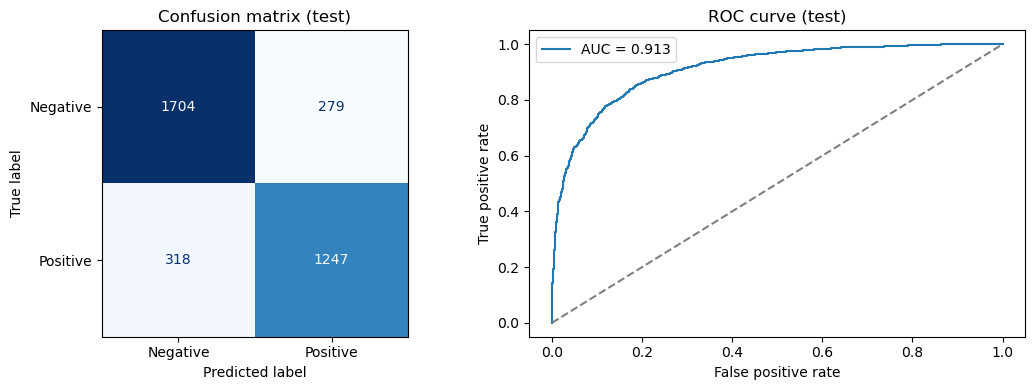

In [46]:
pos_idx = list(le.classes_).index("Positive")   # column of the "Positive" class in predict_proba
y_pred_enc = best_model.predict(X_test)
y_pred = le.inverse_transform(y_pred_enc)       # back to string labels
proba_test = best_model.predict_proba(X_test)[:, pos_idx]

base_pred_test = le.inverse_transform(baseline.predict(X_test))

test_metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "roc_auc": roc_auc_score(y_test == "Positive", proba_test),
    "baseline_accuracy": accuracy_score(y_test, base_pred_test),
}
print({k: round(float(v), 4) for k, v in test_metrics.items()})
print()
print(classification_report(y_test, y_pred, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_test == "Positive", proba_test)
axes[1].plot(fpr, tpr, label=f"AUC = {test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 11. Packaging for the tkinter app

Three things are saved to `semantic_artifacts/`: the trained classifier, a local copy of the embedding model (so the
desktop app works offline during a demo), and a metadata file. A small wrapper module, `semantic_predictor.py`, is
written next to the notebook. It validates input, predicts, and explains a prediction phrase by phrase. The explanation
works by **occlusion**: split the headline into phrases, remove one at a time, and see how much P(Positive) changes.

Files are written with `encoding="utf-8"` (without it, Windows can fail on non-ASCII characters and leave an empty file).

In [47]:
embedder.save(str(ARTIFACT_DIR / "embedder"))
joblib.dump(best_model, ARTIFACT_DIR / "semantic_classifier.joblib", compress=3)
joblib.dump(le, ARTIFACT_DIR / "label_encoder.joblib")

source_hash = hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest()
meta = {
    "model_version": "semantic-1.0",
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "task": "Binary sentiment (Positive / Negative) of Philippine news headlines; context-aware",
    "classes": [str(c) for c in le.classes_],
    "classifier": best_name,
    "best_params": best_params,
    "teacher_model": TEACHER_MODEL,
    "embedder_model": EMBEDDER_MODEL,
    "min_teacher_confidence": MIN_TEACHER_CONF,
    "sample_size": int(len(df)),
    "labeled_rows": int(len(labeled)),
    "train_rows": int(len(idx_train)),
    "test_rows": int(len(idx_test)),
    "test_metrics": {k: float(v) for k, v in test_metrics.items()},
    "seed": SEED,
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "torch": str(torch.__version__), "transformers": transformers.__version__},
    "source_file": str(DATA_PATH),
    "source_sha256": source_hash,
    "warning": ("Labels come from a pretrained sentiment model (the teacher), not human annotators. "
                "Metrics measure agreement with those labels. Not for financial or other high-stakes decisions."),
}
(ARTIFACT_DIR / "model_metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

PREDICTOR_PY = r'''"""semantic_predictor.py - inference wrapper for the context-aware (semantic) sentiment model."""
import json
import re
from pathlib import Path

import joblib
import numpy as np
from sentence_transformers import SentenceTransformer

MAX_CHARS = 300
_CLAUSE_SPLIT = re.compile(
    r"[,;:]|\s[-\u2013\u2014]\s|\b(?:but|while|whereas|although|though|however)\b", flags=re.IGNORECASE
)


def validate_text(text):
    """Return a cleaned headline or raise ValueError with a readable message."""
    if not isinstance(text, str):
        raise ValueError("Headline must be text.")
    text = " ".join(text.split())
    if not text:
        raise ValueError("Headline is empty.")
    if len(text) > MAX_CHARS:
        raise ValueError(f"Headline is too long ({len(text)} characters; the limit is {MAX_CHARS}).")
    return text


def split_phrases(text):
    """Split a headline into phrases: clauses at commas / 'but' / 'while' ..., else chunks of 3 words."""
    parts = [p.strip() for p in _CLAUSE_SPLIT.split(text) if p and p.strip()]
    if len(parts) >= 2:
        return parts
    words = text.split()
    if len(words) <= 4:
        return [text.strip()]
    return [" ".join(words[i:i + 3]) for i in range(0, len(words), 3)]


class SemanticSentimentPredictor:
    def __init__(self, artifact_dir="semantic_artifacts"):
        folder = Path(artifact_dir)
        self.meta = json.loads((folder / "model_metadata.json").read_text(encoding="utf-8"))
        local_embedder = folder / "embedder"
        self.embedder = SentenceTransformer(str(local_embedder) if local_embedder.exists()
                                            else self.meta["embedder_model"])
        self.clf = joblib.load(folder / "semantic_classifier.joblib")
        encoder_path = folder / "label_encoder.joblib"
        if encoder_path.exists():
            self.classes_ = [str(c) for c in joblib.load(encoder_path).classes_]
        else:
            self.classes_ = [str(c) for c in self.meta["classes"]]
        self._pos = self.classes_.index("Positive")

    def _proba(self, texts):
        vectors = self.embedder.encode(list(texts), batch_size=64, convert_to_numpy=True,
                                       normalize_embeddings=True, show_progress_bar=False)
        return self.clf.predict_proba(vectors)

    def predict_one(self, text):
        text = validate_text(text)
        proba = self._proba([text])[0]
        return {
            "headline": text,
            "prediction": self.classes_[int(proba.argmax())],
            "confidence": float(proba.max()),
            "probabilities": {c: float(p) for c, p in zip(self.classes_, proba)},
        }

    def predict_labels(self, texts):
        """Fast batch prediction: returns a list of 'Positive' / 'Negative' labels."""
        proba = self._proba([validate_text(t) for t in texts])
        return [self.classes_[int(i)] for i in proba.argmax(axis=1)]

    def explain_one(self, text, max_items=8):
        """Phrase-by-phrase breakdown.

        alone_pos : P(Positive) of the phrase read on its own
        impact    : P(Positive of full headline) - P(Positive with this phrase removed)
                    > 0 means the phrase pushes the headline toward Positive, < 0 toward Negative
        """
        text = validate_text(text)
        parts = split_phrases(text)
        p_full = float(self._proba([text])[0][self._pos])
        if len(parts) == 1:
            return [{"order": 0, "phrase": parts[0], "alone_pos": p_full, "impact": p_full - 0.5,
                     "pushes_toward": "Positive" if p_full >= 0.5 else "Negative"}]
        without = [" ".join(parts[:i] + parts[i + 1:]) for i in range(len(parts))]
        probs = self._proba(parts + without)[:, self._pos]
        alone, removed = probs[:len(parts)], probs[len(parts):]
        items = []
        for i, (phrase, a, r) in enumerate(zip(parts, alone, removed)):
            impact = p_full - float(r)
            items.append({"order": i, "phrase": phrase, "alone_pos": float(a), "impact": impact,
                          "pushes_toward": "Positive" if impact >= 0 else "Negative"})
        items.sort(key=lambda d: abs(d["impact"]), reverse=True)
        return items[:max_items]
'''
Path("semantic_predictor.py").write_text(PREDICTOR_PY, encoding="utf-8")

import importlib

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
importlib.invalidate_caches()
if "semantic_predictor" in sys.modules:
    importlib.reload(sys.modules["semantic_predictor"])
from semantic_predictor import SemanticSentimentPredictor

predictor = SemanticSentimentPredictor(str(ARTIFACT_DIR))

# Packaging proof: the model reloaded from disk must give the same probabilities as the one in memory.
sample_idx = idx_test[:25]
reloaded = predictor._proba(labeled["headline"].iloc[sample_idx])
in_memory = best_model.predict_proba(X_all[sample_idx])
print("Reloaded model matches in-memory model:", bool(np.allclose(reloaded, in_memory, atol=1e-4)))
print("Files written:", sorted(p.name for p in ARTIFACT_DIR.iterdir()), "+ semantic_predictor.py")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Reloaded model matches in-memory model: True
Files written: ['embedder', 'label_encoder.joblib', 'model_metadata.json', 'semantic_classifier.joblib'] + semantic_predictor.py


## 12. Negation stress test — rule-based vs semantic

This is the heart of the comparison. Each sentence below was written by hand with a **known** sentiment (not produced by
any model), so it is an independent check. Three groups:

* **negation** — a negation word flips the meaning ("not bad", "no longer a problem", "fail to impress")
* **domain** — news knowledge decides the sentiment ("typhoon", "corruption" are negative topics, but "spares" or "no
  corruption found" reverse it; "new high" is bad for prices)
* **plain** — ordinary headlines with no trick

The rule-based model is loaded from the previous notebook's saved files (`news_sentiment_artifacts/`). If they are not
in this folder the rule-based column is simply skipped. The teacher is shown too, for transparency.

Could not load the rule-based model: ModuleNotFoundError No module named 'news_predictor'


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,headline,expected,kind,semantic,semantic_ok,teacher,teacher_ok
0,The president is not bad.,Positive,negation,Negative,NO,Positive,yes
1,The new policy did not fail.,Positive,negation,Negative,NO,Positive,yes
2,Inflation is no longer a problem for families.,Positive,negation,Negative,NO,Positive,yes
3,No corruption found in the audit.,Positive,negation,Negative,NO,Positive,yes
4,Typhoon spares Metro Manila.,Positive,negation,Negative,NO,Positive,yes
5,Hospital reports no new cases of infection.,Positive,negation,Negative,NO,Negative,NO
6,The mayor's response was not a disappointment.,Positive,negation,Negative,NO,Positive,yes
7,Crime rate drops to its lowest level in a decade.,Positive,plain,Negative,NO,Negative,NO
8,Flood damage was far less severe than feared.,Positive,plain,Negative,NO,Negative,NO
9,Unemployment falls to a record low.,Positive,plain,Negative,NO,Negative,NO


Accuracy on the hand-written stress set (24 sentences):
{'semantic': 0.5, 'teacher': 0.75}


,semantic,teacher
kind,,
domain,0.333,0.667
negation,0.417,0.833
plain,0.667,0.667


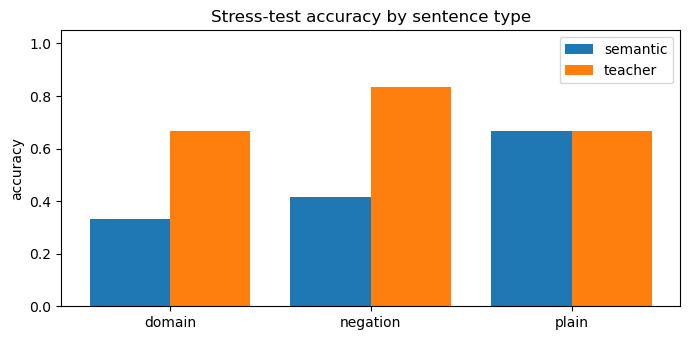

In [48]:
import sys
from pathlib import Path

if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from semantic_predictor import SemanticSentimentPredictor

if "predictor" not in globals():
    predictor = SemanticSentimentPredictor(str(ARTIFACT_DIR))

def load_rule_based():
    artifact = Path("news_sentiment_artifacts/ph_news_sentiment_pipeline.joblib")
    if not artifact.exists():
        print("Rule-based model files not found in this folder -> rule-based columns will be skipped.")
        return None
    try:
        if str(Path.cwd()) not in sys.path:
            sys.path.insert(0, str(Path.cwd()))
        from news_predictor import NewsSentimentPredictor  # written by the rule-based notebook
        return NewsSentimentPredictor(str(artifact))
    except Exception as exc:
        print("Could not load the rule-based model:", type(exc).__name__, exc)
        return None


def rule_predict(text):
    if rule_model is None:
        return None
    try:
        return rule_model.predict_one(text)["prediction"]
    except Exception:
        return "ERROR"


def teacher_predict(texts):
    out = get_teacher()(list(texts), truncation=True, max_length=64)
    return ["Positive" if o["label"].upper().startswith("POS") else "Negative" for o in out]


rule_model = load_rule_based()

STRESS = [
    # (headline, expected sentiment, kind)
    ("The president is not bad.", "Positive", "negation"),
    ("The new policy did not fail.", "Positive", "negation"),
    ("Inflation is no longer a problem for families.", "Positive", "negation"),
    ("No corruption found in the audit.", "Positive", "negation"),
    ("Typhoon spares Metro Manila.", "Positive", "negation"),
    ("Hospital reports no new cases of infection.", "Positive", "negation"),
    ("The mayor's response was not a disappointment.", "Positive", "negation"),
    ("Crime rate drops to its lowest level in a decade.", "Positive", "plain"),
    ("Flood damage was far less severe than feared.", "Positive", "plain"),
    ("Unemployment falls to a record low.", "Positive", "plain"),
    ("Residents welcome the long-awaited flood control project.", "Positive", "plain"),
    ("Death toll falls to zero after the lockdown ends.", "Positive", "domain"),
    ("The project is not good enough.", "Negative", "negation"),
    ("The senator was not honest about the funds.", "Negative", "negation"),
    ("Not a single hospital was spared from the flood.", "Negative", "negation"),
    ("The scandal is far from over.", "Negative", "negation"),
    ("Residents are not happy with the delayed relief.", "Negative", "negation"),
    ("Officials fail to impress investors.", "Negative", "plain"),
    ("Unemployment rises as factories close.", "Negative", "plain"),
    ("Peso weakens as inflation surges.", "Negative", "plain"),
    ("Audit uncovers corruption in the agency.", "Negative", "plain"),
    ("Commuters stranded as the strike paralyzes transport.", "Negative", "plain"),
    ("Rice prices hit a new high.", "Negative", "domain"),
    ("Typhoon leaves thousands without power.", "Negative", "domain"),
]

stress = pd.DataFrame(STRESS, columns=["headline", "expected", "kind"])
stress["semantic"] = predictor.predict_labels(stress["headline"])
stress["teacher"] = teacher_predict(stress["headline"])
stress["rule_based"] = [rule_predict(t) for t in stress["headline"]]

model_cols = [c for c in ("rule_based", "semantic", "teacher") if stress[c].notna().all()]
for c in model_cols:
    stress[c + "_ok"] = np.where(stress[c] == stress["expected"], "yes", "NO")

display(stress[["headline", "expected", "kind"] + [x for c in model_cols for x in (c, c + "_ok")]])

acc_overall = {c: float((stress[c] == stress["expected"]).mean()) for c in model_cols}
acc_by_kind = pd.DataFrame({c: (stress[c] == stress["expected"]).groupby(stress["kind"]).mean() for c in model_cols})
print("Accuracy on the hand-written stress set (%d sentences):" % len(stress))
print({k: round(v, 3) for k, v in acc_overall.items()})
display(acc_by_kind.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
width = 0.8 / len(model_cols)
for j, c in enumerate(model_cols):
    ax.bar(np.arange(len(acc_by_kind)) + j * width, acc_by_kind[c], width=width, label=c)
ax.set_xticks(np.arange(len(acc_by_kind)) + width * (len(model_cols) - 1) / 2)
ax.set_xticklabels(acc_by_kind.index)
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_title("Stress-test accuracy by sentence type")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Phrase-by-phrase explanation

For each headline the app can say *why*: the headline is split into phrases (clauses at commas or "but" / "while";
otherwise chunks of three words). Each phrase gets two numbers:

* **alone P(Positive)** — how positive the phrase reads by itself
* **impact** — P(Positive) of the full headline minus P(Positive) with that phrase removed. Positive impact = the phrase
  pushes the headline toward Positive; negative impact = toward Negative.

This replaces the rule-based notebook's "top weighted words" with an explanation of the *specific* headline.


'The president is not bad'
  -> Negative (85%)
     The president is                                 alone P(pos)=0.92  impact=-0.74  -> Negative
     not bad                                          alone P(pos)=0.89  impact=-0.77  -> Negative

'Officials fail to impress investors, but residents welcome the new bridge'
  -> Negative (51%)
     Officials fail to impress investors              alone P(pos)=0.03  impact=-0.50  -> Negative
     residents welcome the new bridge                 alone P(pos)=1.00  impact=+0.46  -> Positive

'Inflation eases as oil prices fall'
  -> Negative (96%)
     Inflation eases as                               alone P(pos)=0.80  impact=+0.04  -> Positive
     oil prices fall                                  alone P(pos)=0.00  impact=-0.76  -> Negative

'Typhoon leaves thousands without power while rescuers work through the night'
  -> Negative (93%)
     Typhoon leaves thousands without power           alone P(pos)=0.04  impact=-0.45  -> Negative
    

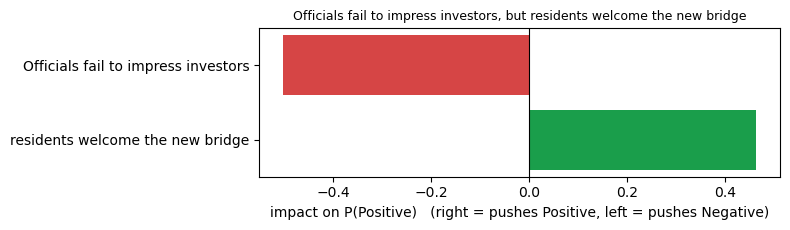

In [49]:
DEMO = [
    "The president is not bad",
    "Officials fail to impress investors, but residents welcome the new bridge",
    "Inflation eases as oil prices fall",
    "Typhoon leaves thousands without power while rescuers work through the night",
]

for headline in DEMO:
    result = predictor.predict_one(headline)
    print(f"\n{headline!r}\n  -> {result['prediction']} ({result['confidence']:.0%})")
    for item in sorted(predictor.explain_one(headline), key=lambda d: d["order"]):
        print(f"     {item['phrase'][:48]:<48} alone P(pos)={item['alone_pos']:.2f}  "
              f"impact={item['impact']:+.2f}  -> {item['pushes_toward']}")

items = sorted(predictor.explain_one(DEMO[1]), key=lambda d: d["order"])
fig, ax = plt.subplots(figsize=(8, 0.6 * len(items) + 1.2))
ax.barh([i["phrase"] for i in items][::-1], [i["impact"] for i in items][::-1],
        color=["#1a9e4b" if i["impact"] >= 0 else "#d64545" for i in items][::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("impact on P(Positive)   (right = pushes Positive, left = pushes Negative)")
ax.set_title(DEMO[1], fontsize=9)
plt.tight_layout()
plt.show()

## 14. Validation against headlines you label by hand

Everything so far is measured against the teacher or a short hand-written list. The most convincing evidence is a sample
of **real headlines labelled by a human**. This cell creates `human_label_sample.csv` (150 random *test* headlines with an
empty `human_label` column). Open it in Excel, type `Positive` or `Negative` for each row (skip any you are unsure
about), save, and run this cell again: it then scores the rule-based model and the semantic model against **your**
labels. This also addresses the biggest limitation of the rule-based notebook (no human labels).

In [50]:
HUMAN_FILE = Path("human_label_sample.csv")

if not HUMAN_FILE.exists():
    sample = labeled.iloc[idx_test].sample(n=min(150, len(idx_test)), random_state=SEED)[["headline"]]
    sample["human_label"] = ""
    sample.to_csv(HUMAN_FILE, index=False, encoding="utf-8-sig")
    print(f"Created {HUMAN_FILE} with {len(sample)} headlines. Fill in the 'human_label' column, then re-run this cell.")
    human = None
else:
    human = pd.read_csv(HUMAN_FILE, encoding="utf-8-sig")
    human["human_label"] = human["human_label"].astype(str).str.strip().str.capitalize()
    human = human[human["human_label"].isin(["Positive", "Negative"])].reset_index(drop=True)
    if len(human) < 30:
        print(f"Only {len(human)} labelled rows found; label at least 30 for a meaningful comparison.")
        human = None

human_results = {}
if human is not None:
    human["semantic"] = predictor.predict_labels(human["headline"])
    rows = {"semantic": human["semantic"]}
    if rule_model is not None:
        human["rule_based"] = [rule_predict(t) for t in human["headline"]]
        rows["rule_based"] = human["rule_based"]
    for name, preds in rows.items():
        human_results[name] = {"accuracy": accuracy_score(human["human_label"], preds),
                               "macro_f1": f1_score(human["human_label"], preds, average="macro")}
    print(f"Scored against {len(human)} human-labelled headlines:")
    display(pd.DataFrame(human_results).T.round(3))

Created human_label_sample.csv with 150 headlines. Fill in the 'human_label' column, then re-run this cell.


## 15. Robustness / error handling

Bad input must produce a clear message, never a crash.

In [52]:
ROBUST_CASES = {
    "empty string": "",
    "spaces only": "   ",
    "very long text": "word " * 200,
    "emoji only": "\U0001F600\U0001F600\U0001F600",
    "digits only": "12345 67890",
    "None": None,
    "a number": 123,
    "negation + punctuation": "Not bad!!! (really)",
}
unexpected = 0
for name, value in ROBUST_CASES.items():
    try:
        r = predictor.predict_one(value)
        status = f"OK -> {r['prediction']} ({r['confidence']:.0%})"
    except ValueError as exc:
        status = f"rejected cleanly: {exc}"
    except Exception as exc:  # anything else is a bug
        status = f"UNEXPECTED {type(exc).__name__}: {exc}"
        unexpected += 1
    print(f"{name:<24} {status}")
assert unexpected == 0, "The predictor raised an unexpected exception."

empty string             rejected cleanly: Headline is empty.
spaces only              rejected cleanly: Headline is empty.
very long text           rejected cleanly: Headline is too long (999 characters; the limit is 300).
emoji only               OK -> Positive (99%)
digits only              OK -> Positive (90%)
None                     rejected cleanly: Headline must be text.
a number                 rejected cleanly: Headline must be text.
negation + punctuation   OK -> Positive (95%)


## 16. Limitations & responsible use

1. **Labels are not human-annotated.** The teacher model learned sentiment from movie-review sentences. News headlines are
   a different domain, so some teacher labels are debatable ("Rice prices hit a new high" can read as positive to a model
   that does not know prices are bad news). Section 14 exists to measure this against human labels.
2. **Sentiment is not the same as "good news".** A headline can be negative in tone but good for a reader, and the reverse.
3. **English only.** Filipino, Taglish, slang and regional-language headlines are untested.
4. **Neutral headlines are dropped**, so the model always answers Positive or Negative even for factual headlines.
5. **Phrase explanations are heuristic.** Occlusion shows how the model's score reacts to removing a phrase, which is
   association, not proof of causation, and the phrase splitter is simple (commas, "but", "while", otherwise 3-word chunks).
6. **No financial use.** A sentiment score must never be used as a trading signal; markets move on far more than headline wording.
7. **Transparency.** The app always shows the class, the probabilities and the phrase breakdown, and states that it is an
   automated aid.

## 17. Summary & files

In [53]:
print("=" * 78)
print("SUMMARY (all numbers come from this run)")
print("=" * 78)
print(f"Data          : {len(labeled):,} labelled headlines ({len(idx_train):,} train / {len(idx_test):,} test), "
      f"teacher confidence >= {MIN_TEACHER_CONF}")
print(f"Model         : {best_name} on {EMBEDDER_MODEL.split('/')[-1]} sentence embeddings "
      f"(CV macro-F1 {candidates[best_name]['cv_f1']:.3f})")
print(f"Test set      : accuracy {test_metrics['accuracy']:.3f} | macro-F1 {test_metrics['macro_f1']:.3f} | "
      f"ROC-AUC {test_metrics['roc_auc']:.3f}  (agreement with the teacher's labels)")
print(f"Stress test   : " + " | ".join(f"{k} {v:.0%}" for k, v in acc_overall.items())
      + f"  ({len(stress)} hand-written sentences)")
if "scratch_results" in globals():
    print(f"From-scratch NN : validation accuracy after 30 epochs (inner split of train) -> "
          f"Adam {scratch_results['adam_val_acc']:.3f} | SGD {scratch_results['sgd_val_acc']:.3f}")
if human_results:
    print("Human labels  : " + " | ".join(f"{k} acc {v['accuracy']:.0%}" for k, v in human_results.items()))
print("\nCaveat: labels come from a pretrained teacher model, not human annotators, "
      "so test-set numbers measure agreement with it.")
print("\nFiles created: semantic_predictor.py, semantic_artifacts/, semantic_cache/, human_label_sample.csv")
print("Next: run the desktop app ->  python app_tk.py")

SUMMARY (all numbers come from this run)
Data          : 17,737 labelled headlines (14,189 train / 3,548 test), teacher confidence >= 0.8
Model         : MLP (1 hidden layer) on all-MiniLM-L6-v2 sentence embeddings (CV macro-F1 0.831)
Test set      : accuracy 0.832 | macro-F1 0.829 | ROC-AUC 0.913  (agreement with the teacher's labels)
Stress test   : semantic 50% | teacher 75%  (24 hand-written sentences)

Caveat: labels come from a pretrained teacher model, not human annotators, so test-set numbers measure agreement with it.

Files created: semantic_predictor.py, semantic_artifacts/, semantic_cache/, human_label_sample.csv
Next: run the desktop app ->  python app_tk.py
